# Comparare performanță pe testul din același set de date

**1. Descărcare dataset**

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/kermany2018")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'kermany2018' dataset.
Path to dataset files: /kaggle/input/kermany2018


**2. Mutare dataset**

In [2]:
import os
import shutil

BASE = "/content/oct"
RAW = os.path.join(BASE, "raw")

os.makedirs(BASE, exist_ok=True)

shutil.copytree(path, RAW, dirs_exist_ok=True)

print("RAW structure:")
for root, dirs, files in os.walk(RAW):
    print(root, dirs[:5])
    break


RAW structure:
/content/oct/raw ['oct2017', 'OCT2017 ']


# Model de clasificare a imaginilor OCT folosind MobileNetV2

**1. Încărcare model**

In [3]:
from tensorflow.keras.models import load_model

# Încarcă modelul Keras
model_keras = load_model("/content/oct_cnn_model_MobileNetV2.h5")
model_keras.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,110 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 2 (12.00 B)

**2. Testare**

In [5]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import tensorflow as tf
import os


# Parametri
BATCH_SIZE = 32
class_names = ["CNV", "DRUSEN", "NORMAL"]


# Functia de preprocesare
import cv2

TARGET_SIZE = (224, 224)
def preprocess_oct(image):
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = cv2.resize(image, TARGET_SIZE)
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8) if image.max() <= 1.0 else image.astype(np.uint8)
    image = cv2.medianBlur(image, 3)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    image = clahe.apply(image)
    image = image.astype("float32") / 255.0
    return np.stack([image, image, image], axis=-1)


# Creez lista cu imagini si etichete
ROOT = "/content/oct/raw/OCT2017 /test"
paths = []
labels = []

for idx, cls in enumerate(class_names):
    folder = f"{ROOT}/{cls}"
    for fname in os.listdir(folder):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')):
            paths.append(os.path.join(folder, fname))
            labels.append(idx)

labels = np.array(labels)

# Batch-by-batch predict
keras_preds = []

for i in tqdm(range(0, len(paths), BATCH_SIZE), desc="Predicting batches"):
    batch_paths = paths[i:i+BATCH_SIZE]
    X_batch = []
    for p in batch_paths:
        img = tf.keras.utils.load_img(p, target_size=TARGET_SIZE)
        img = tf.keras.utils.img_to_array(img)
        img = preprocess_oct(img)
        X_batch.append(img)
    X_batch = np.array(X_batch)
    preds = np.argmax(model_keras.predict(X_batch, verbose=0), axis=1)
    keras_preds.extend(preds)

keras_preds = np.array(keras_preds)



Predicting batches: 100%|██████████| 23/23 [00:19<00:00,  1.21it/s]


**3. Afișare rezultate**

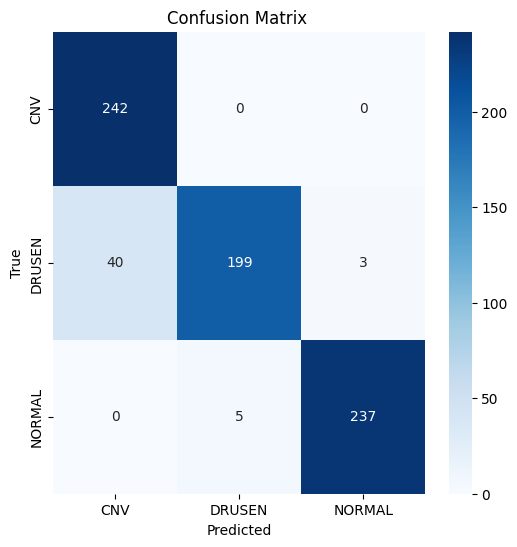


Classification Report :

              precision    recall  f1-score   support

         CNV       0.86      1.00      0.92       242
      DRUSEN       0.98      0.82      0.89       242
      NORMAL       0.99      0.98      0.98       242

    accuracy                           0.93       726
   macro avg       0.94      0.93      0.93       726
weighted avg       0.94      0.93      0.93       726


=== Acuratețe per clasă ===
CNV: 1.0000
DRUSEN: 0.8223
NORMAL: 0.9793

 Test Accuracy: 93.39%


In [7]:
from sklearn.metrics import classification_report
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# clase  (index 0, 2, 3)
keep_idx = [0, 1,2]
class_names_filtered = ["CNV", "DRUSEN", "NORMAL"]

# Matrice confuzie
cm = confusion_matrix(labels, keras_preds)
cm_filtered = cm[np.ix_(keep_idx, keep_idx)]

plt.figure(figsize=(6,6))
sns.heatmap(cm_filtered, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_filtered, yticklabels=class_names_filtered)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix ")
plt.show()

# Raport
mask = np.isin(labels, keep_idx) & np.isin(keras_preds, keep_idx)

y_true_filtered = labels[mask]
y_pred_filtered = keras_preds[mask]


report_filtered = classification_report(
    y_true_filtered,
    y_pred_filtered,
    labels=keep_idx,
    target_names=class_names_filtered
)

print("\nClassification Report :\n")
print(report_filtered)


# Acuratețe per clasă
class_acc_filtered = cm.diagonal()[keep_idx] / cm.sum(axis=1)[keep_idx]
print("\n=== Acuratețe per clasă ===")
for cls, acc in zip(class_names_filtered, class_acc_filtered):
    print(f"{cls}: {acc:.4f}")


# Acuratețe globală
acc_total_filtered = accuracy_score(y_true_filtered, y_pred_filtered)
print(f"\n Test Accuracy: {acc_total_filtered*100:.2f}%")



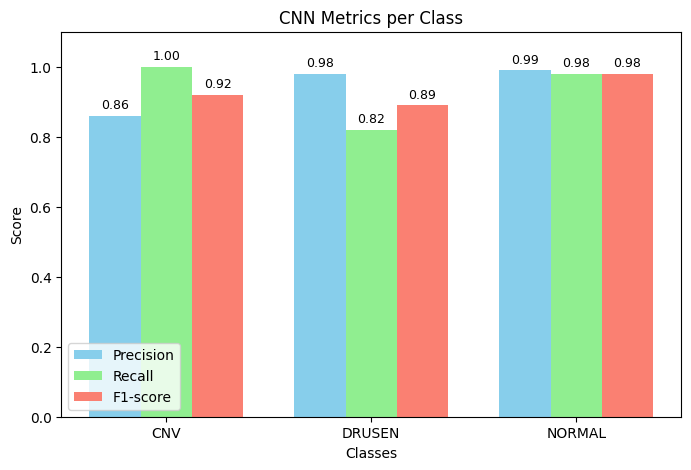

In [9]:
import matplotlib.pyplot as plt
import numpy as np

classes = ["CNV",  "DRUSEN", "NORMAL"]

precision = [0.86,  0.98, 0.99]
recall    = [1,  0.82, 0.98]
f1_score  = [0.92,  0.89, 0.98]

x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width, precision, width, label='Precision', color='skyblue')
rects2 = ax.bar(x, recall, width, label='Recall', color='lightgreen')
rects3 = ax.bar(x + width, f1_score, width, label='F1-score', color='salmon')

ax.set_ylabel('Score')
ax.set_xlabel('Classes')
ax.set_title('CNN Metrics per Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0,1.1)
ax.legend()

# Afișez scorurile
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.show()


# Model de clasificare a imaginilor OCT folosind ResNet18

**1. Încărcare model**

In [10]:
import torch
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pt_model = torch.load(
    '/content/oct_cnn_model_ResNet18.pth',
    map_location=device,
    weights_only=False
)

pt_model.eval()


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

**2. Testare**

In [12]:
import torch
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Parametri
BATCH_SIZE = 32
class_names = ["CNV",  "DRUSEN", "NORMAL"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dataset PyTorch
class OCTDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        label = self.labels[idx]
        return img, label

# Creez dataset și dataloader
from torchvision import transforms

transform_pt = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

dataset_pt = OCTDataset(paths, labels, transform=transform_pt)
dataloader_pt = DataLoader(dataset_pt, batch_size=BATCH_SIZE, shuffle=False)


# Predict batch-by-batch
pt_model.to(DEVICE)
pt_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, lbls in tqdm(dataloader_pt, desc="Predicting PyTorch batches"):
        imgs = imgs.to(DEVICE)
        outputs = pt_model(imgs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(lbls.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)



Predicting PyTorch batches: 100%|██████████| 23/23 [00:05<00:00,  4.60it/s]


**3. Afișare rezultate**

Test Accuracy: 99.45%


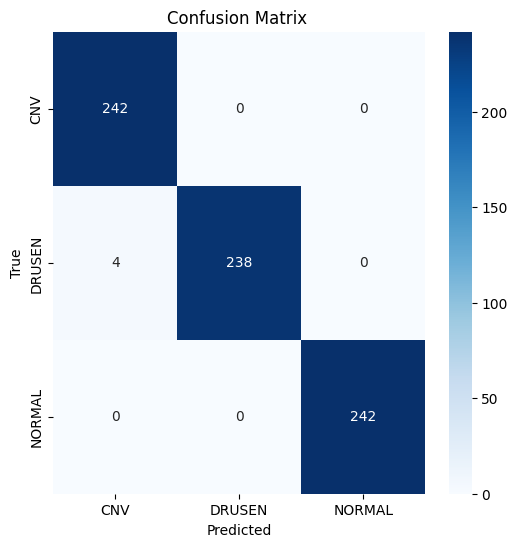


Classification Report :

              precision    recall  f1-score   support

         CNV       0.98      1.00      0.99       242
      DRUSEN       1.00      0.98      0.99       242
      NORMAL       1.00      1.00      1.00       242

    accuracy                           0.99       726
   macro avg       0.99      0.99      0.99       726
weighted avg       0.99      0.99      0.99       726


=== Acuratețe per clasă  ===
CNV: 1.0000
DRUSEN: 0.9835
NORMAL: 1.0000


In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Indici clase păstrate
keep_idx = [0, 1, 2]
class_names_filtered = ["CNV", "DRUSEN", "NORMAL"]

# Filtrez valorile
all_labels_filtered = all_labels[np.isin(all_labels, keep_idx)]
all_preds_filtered  = all_preds[np.isin(all_labels, keep_idx)]

# Acuratețe globală
acc_total_filtered = accuracy_score(all_labels_filtered, all_preds_filtered)
print(f"Test Accuracy: {acc_total_filtered*100:.2f}%")

# Matrice confuzie
cm_filtered = confusion_matrix(all_labels_filtered, all_preds_filtered, labels=keep_idx)
plt.figure(figsize=(6,6))
sns.heatmap(cm_filtered, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_filtered, yticklabels=class_names_filtered)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix ")
plt.show()

# Raport clasificare
report_filtered = classification_report(all_labels_filtered, all_preds_filtered, labels=keep_idx, target_names=class_names_filtered)
print("\nClassification Report :\n")
print(report_filtered)

# Acuratețe per clasă
class_acc_filtered = cm_filtered.diagonal() / cm_filtered.sum(axis=1)
print("\n=== Acuratețe per clasă  ===")
for cls, acc in zip(class_names_filtered, class_acc_filtered):
    print(f"{cls}: {acc:.4f}")


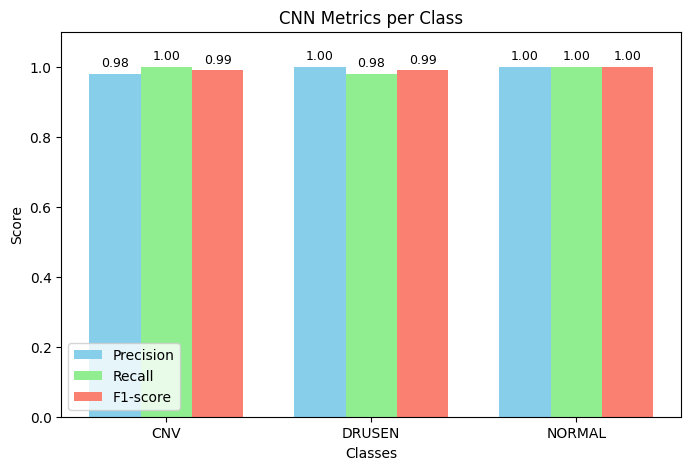

In [14]:
import matplotlib.pyplot as plt
import numpy as np

classes = ["CNV",  "DRUSEN", "NORMAL"]

precision = [0.98, 1, 1]
recall    = [1,  0.98, 1]
f1_score  = [0.99,  0.99, 1]

x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width, precision, width, label='Precision', color='skyblue')
rects2 = ax.bar(x, recall, width, label='Recall', color='lightgreen')
rects3 = ax.bar(x + width, f1_score, width, label='F1-score', color='salmon')

ax.set_ylabel('Score')
ax.set_xlabel('Classes')
ax.set_title('CNN Metrics per Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0,1.1)
ax.legend()

# Afișez scorurile
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.show()
